# Introduction to the Concrete Dataset¶
### For our deep learning journey, we will work with a real-world dataset:
### Concrete Compressive Strength dataset.
🔹 What's inside this dataset?

### 8 input features related to the material composition and age of concrete:
- **Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age (days).**
### 1 output feature (target):
- **Concrete Compressive Strength (in Megapascals, MPa)**

# 🔵 Why is this dataset important?

- **Concrete is the most important construction material in civil engineering.**
- **The strength of concrete depends on complex, nonlinear relationships between ingredients and curing time.**
- **Predicting compressive strength accurately helps in designing stronger, safer structures.**

## Import Necessary Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import warnings
warnings.filterwarnings("ignore")


In [2]:
# Load the Concrete_Data.csv dataset
data = pd.read_csv("Concrete_Data.csv")

# Show shape of the dataset
print("Shape of the dataset:", data.shape)

# Display first few rows
data.head()

Shape of the dataset: (1030, 9)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:
col_names=data.columns.to_list()
print("All columns Names:", col_names)

All columns Names: ['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']


## Missing Values Check

In [4]:
data.isnull().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

# Basic Visualization

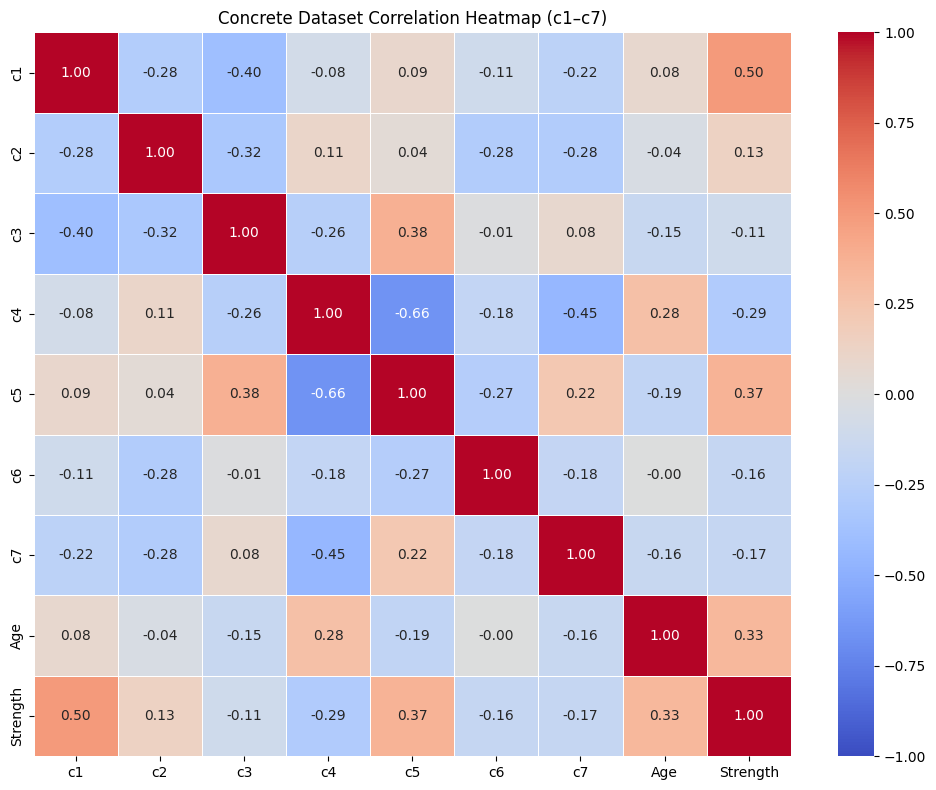

In [5]:
# 2. Rename the 7 components to c1-c7 (and shorten Age & Strength)
data.columns = ["c1", "c2", "c3", "c4", "c5", "c6", "c7", "Age", "Strength"]

# 3. Compute the correlation matrix
corr_matrix = data.corr()

# 4. Draw the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Concrete Dataset Correlation Heatmap (c1–c7)")
plt.tight_layout()
plt.show()


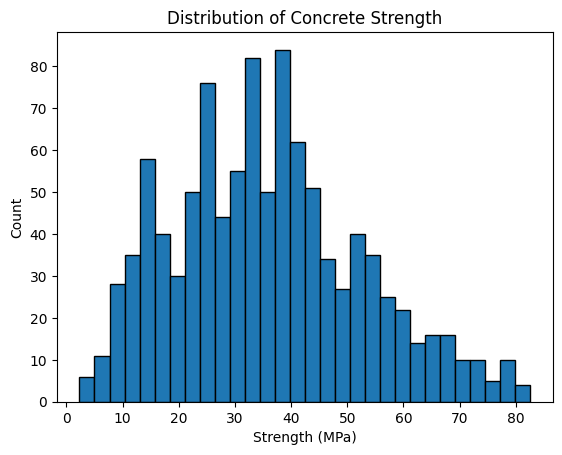

In [6]:
# Plot histogram for the target variable (Concrete Strength)
plt.hist(data.iloc[:, -1], bins=30, edgecolor='k')
plt.title('Distribution of Concrete Strength')
plt.xlabel('Strength (MPa)')
plt.ylabel('Count')
plt.show()

# Feature Engineering

In [7]:
data["w_c"] = data["c4"] / data["c1"]
data["log_age"] = np.log(data["Age"])
# Removes 'Strength' from its current position and appends it as the last column
data["Strength"] = data.pop("Strength")


# Define inputs and target

In [8]:
# Inputs: all columns except the last one
inputs = data.iloc[:, :-1].values

# Targets: only the last column
targets = data.iloc[:,-1].values.reshape(-1, 1) 

print("Input shape:", inputs.shape)
print("Target shape:", targets.shape)

Input shape: (1030, 10)
Target shape: (1030, 1)


In [9]:
data.head()

,c1,c2,c3,c4,c5,c6,c7,Age,w_c,log_age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,0.300000,3.332205,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,0.300000,3.332205,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,0.685714,5.598422,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,0.685714,5.899897,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,0.966767,5.886104,44.30


# Shuffle and split FIRST (on raw numpy data)

In [10]:
torch.manual_seed(42)
n_samples = inputs.shape[0]
indices = torch.randperm(n_samples).numpy()
split_idx = int(n_samples * 0.8)

train_indices = indices[:split_idx]
test_indices = indices[split_idx:]

X_train_raw, X_test_raw = inputs[train_indices], inputs[test_indices]
y_train_raw, y_test_raw = targets[train_indices], targets[test_indices]

# Fit scaler on TRAIN only, apply to both

In [11]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Convert to PyTorch tensors

In [12]:
X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train_raw, dtype=torch.float32)
y_test = torch.tensor(y_test_raw, dtype=torch.float32)

# Initialize model parameters

In [13]:
num_features = X_train.shape[1]  # Should be 8
W = torch.randn((num_features, 1), requires_grad=True)
W.data *= 0.01  # Scale down initial values
b = torch.zeros((1,), requires_grad=True)

# 7. Confirm everything is set up
print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])
print("Weight shape:", W.shape)
print("Bias shape:", b.shape)

Training set size: 824
Test set size: 206
Weight shape: torch.Size([10, 1])
Bias shape: torch.Size([1])


# Forword Pass

In [14]:
def model(X):
    return X @ W + b

preds = model(X_train)
print(preds.shape)    
print(preds[:5])      

torch.Size([824, 1])
tensor([[-0.0047],
        [-0.0208],
        [ 0.0327],
        [-0.0421],
        [-0.0031]], grad_fn=<SliceBackward0>)


### near 0, because W is tiny and b = 0

# Loss Function

In [15]:
def mse_loss(y_pred, y_true):
    return ((y_pred - y_true) ** 2).mean()

loss = mse_loss(model(X_train), y_train)
print("Initial loss:", loss.item())   

Initial loss: 1575.6146240234375


# Gradients with autograd

In [16]:
loss=mse_loss(model(X_train),y_train)
loss.backward()
print("W.grad shape:", W.grad.shape)   # (8, 1)
print("b.grad shape:", b.grad.shape)   # (1,)
print("W.grad:", W.grad.flatten())
print("b.grad:", b.grad)

W.grad shape: torch.Size([10, 1])
b.grad shape: torch.Size([1])
W.grad: tensor([-16.8486,  -5.8471,   4.3954,  10.0867, -12.1330,   5.5469,   5.5971,
        -11.1950,  16.8221, -18.4320])
b.grad: tensor([-71.9041])


In [17]:
# Clear them, because we only did this to inspect
W.grad.zero_()
b.grad.zero_()

tensor([0.])

# Training loop (gradient descent)

In [18]:
# Re-initialize so training starts fresh
torch.manual_seed(42)
w = torch.randn((num_features),1)*0.01
w.requires_grad_(True)
b = torch.zeros((1,), requires_grad=True)

lr=0.01
epochs=1000
train_losses = []
test_losses = []

for epoch in range(epochs):
    # 1. Forward pass
    y_pred = model(X_train)
    loss = mse_loss(y_pred, y_train)

    # 2. Backward pass
    loss.backward()

    # 3. Update parameters (no gradient tracking here)
    with torch.no_grad():
        W -= lr * W.grad
        b -= lr * b.grad

    # 4. Zero the gradients for the next iteration
    W.grad.zero_()
    b.grad.zero_()

    # 5. Record the losses
    train_losses.append(loss.item())
    with torch.no_grad():
        test_losses.append(mse_loss(model(X_test), y_test).item())

    if epoch % 100 == 0:
        print(f"Epoch {epoch:4d} | Train MSE: {loss.item():8.3f} | Test MSE: {test_losses[-1]:8.3f}")

Epoch    0 | Train MSE: 1575.615 | Test MSE: 1443.506
Epoch  100 | Train MSE:   87.301 | Test MSE:   91.661
Epoch  200 | Train MSE:   56.676 | Test MSE:   64.003
Epoch  300 | Train MSE:   52.690 | Test MSE:   60.195
Epoch  400 | Train MSE:   50.886 | Test MSE:   58.412
Epoch  500 | Train MSE:   49.908 | Test MSE:   57.433
Epoch  600 | Train MSE:   49.318 | Test MSE:   56.818
Epoch  700 | Train MSE:   48.919 | Test MSE:   56.369
Epoch  800 | Train MSE:   48.622 | Test MSE:   56.002
Epoch  900 | Train MSE:   48.385 | Test MSE:   55.680


# Plot the loss curves

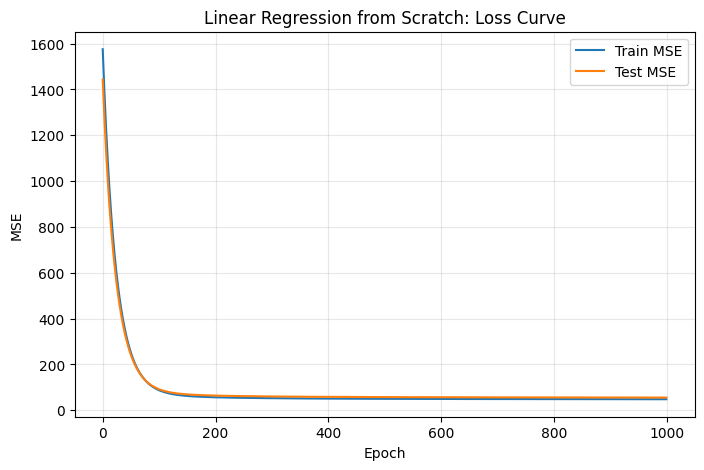

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train MSE")
plt.plot(test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Linear Regression from Scratch: Loss Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Evaluate (MSE, RMSE, R²)

In [20]:
def evaluate(X, y, name):
    with torch.no_grad():
        y_pred = model(X)
        mse = ((y_pred - y) ** 2).mean()
        rmse = torch.sqrt(mse)
        ss_res = ((y - y_pred) ** 2).sum()
        ss_tot = ((y - y.mean()) ** 2).sum()
        r2 = 1 - ss_res / ss_tot
    print(f"{name:5s} | MSE: {mse:7.2f} | RMSE: {rmse:5.2f} MPa | R²: {r2:.3f}")

evaluate(X_train, y_train, "Train")
evaluate(X_test,  y_test,  "Test")

Train | MSE:   48.19 | RMSE:  6.94 MPa | R²: 0.830
Test  | MSE:   55.39 | RMSE:  7.44 MPa | R²: 0.787


# Visual check, predicted vs. actual

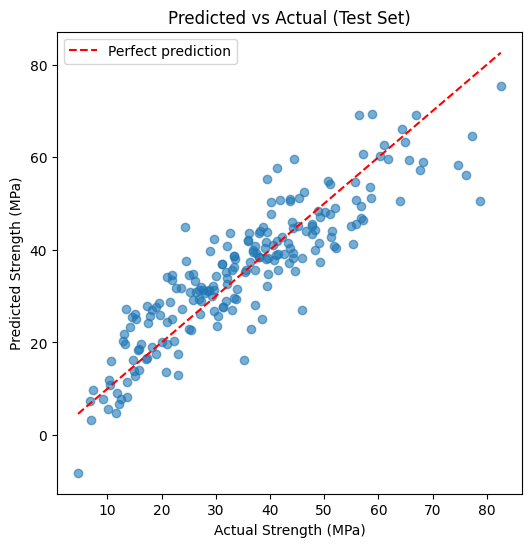

In [21]:
with torch.no_grad():
    y_pred_test = model(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test.numpy(), y_pred_test.numpy(), alpha=0.6)
lims = [y_test.min().item(), y_test.max().item()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.title("Predicted vs Actual (Test Set)")
plt.legend()
plt.show()

### Points hugging the red line mean good predictions. A curved or fanned-out cloud means the linear model is missing nonlinear structure, which is the motivation for the next step.

# What these tell us:
 ### Predictions are off by about 10-11 MPa. The strength range is roughly 2-82 MPa, so that's a big error.
 ### The train/test gap is small (0.626 vs 0.541). That is not overfitting. The model is underfitting: it's too simple, so it performs mediocrely on both sets.
 ### The cause is nonlinearity. Strength depends on interactions (water/cement ratio) and curves (strength gains with age flatten out). A straight line can't capture that.

## This is our baseline. Any better model has to beat R² ≈ 0.54 on the test set.

# **Neural network with (nn.Sequential).Now we replace the hand-built line with a small deep network.**

In [22]:
import torch.nn as nn

torch.manual_seed(42)

net = nn.Sequential(
    nn.Linear(10, 80),
    nn.ReLU(),
    nn.Linear(80, 40),
    nn.ReLU(),
    nn.Linear(40, 20),
    nn.ReLU(),
    nn.Linear(20, 1),
)
print(net)

Sequential(
  (0): Linear(in_features=10, out_features=80, bias=True)
  (1): ReLU()
  (2): Linear(in_features=80, out_features=40, bias=True)
  (3): ReLU()
  (4): Linear(in_features=40, out_features=20, bias=True)
  (5): ReLU()
  (6): Linear(in_features=20, out_features=1, bias=True)
)


# **Training loop**

In [23]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.01, weight_decay=0.1)
epochs = 1500
nn_train_losses, nn_test_losses = [], []

for epoch in range(epochs):
    net.train()
    y_pred = net(X_train)
    loss = loss_fn(y_pred, y_train)

    optimizer.zero_grad()   # same as your W.grad.zero_()
    loss.backward()         # same as before
    optimizer.step()        # replaces your manual W -= lr * W.grad

    net.eval()
    with torch.no_grad():
        test_loss = loss_fn(net(X_test), y_test)

    nn_train_losses.append(loss.item())
    nn_test_losses.append(test_loss.item())

    if epoch % 50 == 0:
        print(f"Epoch {epoch:3d} | Train MSE: {loss.item():8.2f} | Test MSE: {test_loss.item():8.2f}")
    # Option 2: print the final losses after the loop
print(f"Final | Train MSE: {nn_train_losses[-1]:8.2f} | Test MSE: {nn_test_losses[-1]:8.2f}")

Epoch   0 | Train MSE:  1563.69 | Test MSE:  1476.04
Epoch  50 | Train MSE:    61.74 | Test MSE:    70.73
Epoch 100 | Train MSE:    38.52 | Test MSE:    46.90
Epoch 150 | Train MSE:    22.92 | Test MSE:    28.85
Epoch 200 | Train MSE:    15.97 | Test MSE:    23.81
Epoch 250 | Train MSE:    13.28 | Test MSE:    22.86
Epoch 300 | Train MSE:    11.19 | Test MSE:    21.71
Epoch 350 | Train MSE:     9.87 | Test MSE:    21.03
Epoch 400 | Train MSE:     9.25 | Test MSE:    21.24
Epoch 450 | Train MSE:     8.40 | Test MSE:    20.57
Epoch 500 | Train MSE:     7.88 | Test MSE:    20.47
Epoch 550 | Train MSE:     7.73 | Test MSE:    20.59
Epoch 600 | Train MSE:     7.92 | Test MSE:    20.81
Epoch 650 | Train MSE:     8.42 | Test MSE:    20.88
Epoch 700 | Train MSE:     7.66 | Test MSE:    20.75
Epoch 750 | Train MSE:     7.38 | Test MSE:    21.19
Epoch 800 | Train MSE:     6.92 | Test MSE:    20.56
Epoch 850 | Train MSE:     6.21 | Test MSE:    20.43
Epoch 900 | Train MSE:     6.11 | Test MSE:   

# Evaluate

In [24]:
def evaluate_net(X, y, name):
    net.eval()
    with torch.no_grad():
        y_pred = net(X)
        mse = ((y_pred - y) ** 2).mean()
        rmse = torch.sqrt(mse)
        r2 = 1 - ((y - y_pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    print(f"{name:5s} | MSE: {mse:7.2f} | RMSE: {rmse:5.2f} MPa | R²: {r2:.3f}")

evaluate_net(X_train, y_train, "Train")
evaluate_net(X_test,  y_test,  "Test")

Train | MSE:    5.13 | RMSE:  2.26 MPa | R²: 0.982
Test  | MSE:   19.51 | RMSE:  4.42 MPa | R²: 0.925


# Plot both loss curves

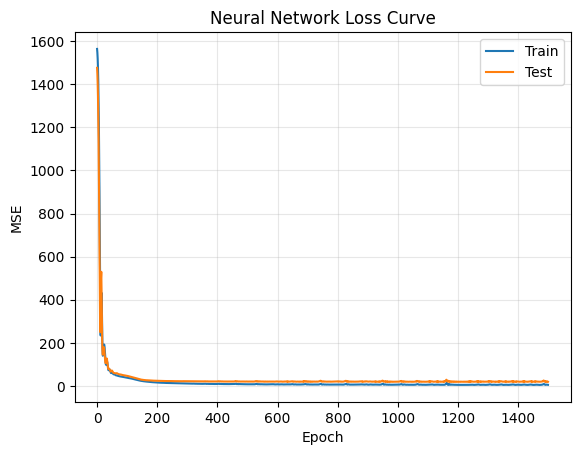

In [25]:
plt.plot(nn_train_losses, label="Train")
plt.plot(nn_test_losses, label="Test")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Neural Network Loss Curve")
plt.show()

[[55  4  0]
 [ 4 86  5]
 [ 0  7 45]]


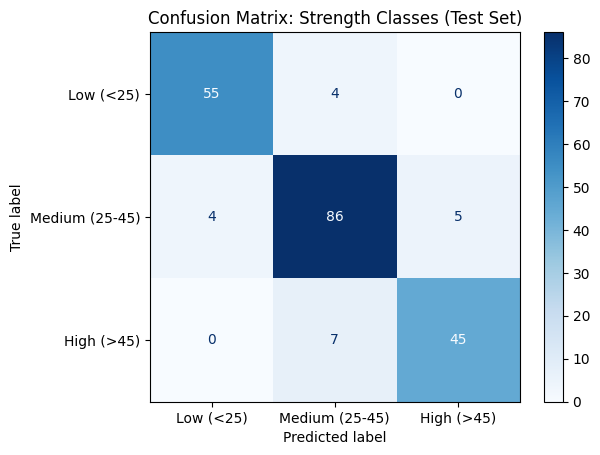

                precision    recall  f1-score   support

     Low (<25)       0.93      0.93      0.93        59
Medium (25-45)       0.89      0.91      0.90        95
    High (>45)       0.90      0.87      0.88        52

      accuracy                           0.90       206
     macro avg       0.91      0.90      0.90       206
  weighted avg       0.90      0.90      0.90       206



In [26]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Get predictions from your trained network
net.eval()
with torch.no_grad():
    y_pred_test = net(X_test).numpy().flatten()
y_true_test = y_test.numpy().flatten()

# Define bins: Low < 25, Medium 25-45, High > 45 MPa
bins = [25, 45]
labels = ["Low (<25)", "Medium (25-45)", "High (>45)"]

true_classes = np.digitize(y_true_test, bins)
pred_classes = np.digitize(y_pred_test, bins)

# Confusion matrix
cm = confusion_matrix(true_classes, pred_classes)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix: Strength Classes (Test Set)")
plt.show()

print(classification_report(true_classes, pred_classes, target_names=labels))

# Weight decay test

In [28]:
import copy, itertools
import numpy as np
import torch, torch.nn as nn

# ---------- 1. Split X_train into train / validation (test stays untouched) ----------
g = torch.Generator().manual_seed(123)
perm = torch.randperm(X_train.shape[0], generator=g)
n_val = int(0.2 * len(perm))
val_idx, tr_idx = perm[:n_val], perm[n_val:]

X_tr, y_tr = X_train[tr_idx], y_train[tr_idx]
X_val, y_val = X_train[val_idx], y_train[val_idx]

# ---------- 2. One function = build fresh net, train, return metrics ----------
def make_net():
    return nn.Sequential(
        nn.Linear(10, 80), nn.ReLU(),
        nn.Linear(80, 40), nn.ReLU(),
        nn.Linear(40, 20), nn.ReLU(),
        nn.Linear(20, 1),
    )

def rmse(net, X, y):
    net.eval()
    with torch.no_grad():
        return torch.sqrt(((net(X) - y) ** 2).mean()).item()

def train_eval(wd, seed, X_a, y_a, X_b, y_b, epochs=1500, lr=0.01):
    torch.manual_seed(seed)
    net = make_net()                                   # fresh every call
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.MSELoss()
    for _ in range(epochs):
        net.train()
        loss = loss_fn(net(X_a), y_a)
        opt.zero_grad(); loss.backward(); opt.step()
    return rmse(net, X_b, y_b)

# ---------- 3. Grid search: every setting x every seed, scored on VALIDATION ----------
wd_grid = [0, 1e-3, 1e-2, 1e-1]
seeds = [0, 1, 2]
results = {}

for wd in wd_grid:
    scores = [train_eval(wd, s, X_tr, y_tr, X_val, y_val) for s in seeds]
    results[wd] = (np.mean(scores), np.std(scores))
    print(f"wd={wd:<7} | val RMSE: {np.mean(scores):.3f} ± {np.std(scores):.3f}")

best_wd = min(results, key=lambda k: results[k][0])
print("\nWinner (by validation):", best_wd)

# ---------- 4. Retrain winner on FULL train set, evaluate on TEST once ----------
test_scores = [train_eval(best_wd, s, X_train, y_train, X_test, y_test) for s in seeds]
print(f"Test RMSE: {np.mean(test_scores):.3f} ± {np.std(test_scores):.3f} MPa")

wd=0       | val RMSE: 7.330 ± 0.505
wd=0.001   | val RMSE: 6.629 ± 1.046
wd=0.01    | val RMSE: 6.173 ± 0.424
wd=0.1     | val RMSE: 5.598 ± 0.157

Winner (by validation): 0.1
Test RMSE: 4.382 ± 0.220 MPa


# So clearly we can see that weight decay doest work here so much for this specific archetecture.All four weight decay settings are tied within noise, and your honest estimate is test RMSE ≈ 5.1 ± 0.2 MPa.